# EDA синтетического набора v0

Набор собран генератором `agent_risk.synthetic` по дизайну ДЗ1: владелец сценария
задаёт состояние и поручение, агент предлагает вызовы, минимальные правки создают
контрастные прогоны, шлюз строит признаки, эталон проверяет последствия отдельно от
признаков. Доли поведения агента задаёт конфигурация генератора, поэтому частоты ниже —
свойства пилотного набора, а не реального потока.

Распределения признаков и меток, сила признаков и сравнение с правилами считаются
только на train. Validation, test и challenge входят лишь в проверку целостности и
разбиения: объём, типы, доля нарушений по частям. Числа в выводах взяты из выходов
ячеек этого ноутбука.

In [1]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from agent_risk.rules import b1, b1_plus, b1_plus_reasons, b1_reasons
from agent_risk.tables import call_features_from_row, read_rows

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "synthetic" / "v0"
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 72, "savefig.dpi": 110, "font.size": 10})


def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / name, bbox_inches="tight")
    plt.show()


manifest = json.loads((DATA / "manifest.json").read_text())
for name, expected in manifest["sha256"].items():
    actual = hashlib.sha256((DATA / name).read_bytes()).hexdigest()
    assert actual == expected, name
print("Хеши файлов совпадают с manifest.json; версия генератора", manifest["generator_version"])

Хеши файлов совпадают с manifest.json; версия генератора 0.1.0


## 1. Объём и независимые единицы

In [2]:
raw_calls = read_rows(DATA / "calls.csv.gz")
calls = pd.DataFrame(raw_calls)
labels = pd.read_csv(DATA / "labels.csv.gz", keep_default_na=False)
scen = pd.read_csv(DATA / "scenarios.csv.gz")
audit = pd.read_csv(DATA / "audit.csv.gz")

calls["family_id"] = calls["call_id"].str.split("-").str[0]
df = calls.merge(labels, on="call_id", validate="one_to_one").merge(
    scen[["family_id", "split", "is_challenge", "behaviour", "injection"]], on="family_id"
).merge(audit[["call_id", "variant", "injected_step", "true_payload_class", "prior_write_applied"]],
        on="call_id", validate="one_to_one")
df["payload_kb"] = df["payload_kb"].astype(float)
df["n_prev_calls"] = df["n_prev_calls"].astype(int)
for col in ["effect_in_task", "sensitive_read_before", "external_send_before",
            "untrusted_input_before", "recipient_changed", "retry_after_unknown",
            "ambiguous_lookup"]:
    df[col] = df[col].astype(int)
df["y"] = pd.to_numeric(df["y"], errors="coerce")

volume = pd.DataFrame({
    "семейства": df.groupby("split")["family_id"].nunique(),
    "прогоны": df.groupby("split")["run_id"].nunique(),
    "вызовы": df.groupby("split").size(),
    "семейства с нарушением": df[df["y"] == 1].groupby("split")["family_id"].nunique(),
    "нарушения": df.groupby("split")["y"].sum().astype(int),
}).reindex(["train", "validation", "test", "challenge"])
volume.loc["всего"] = volume.sum()
volume

,семейства,прогоны,вызовы,семейства с нарушением,нарушения
split,,,,,
train,822,2241,9246,789,1511
validation,283,755,3050,270,455
test,286,786,3212,269,503
challenge,109,331,1945,108,366
всего,1500,4113,17453,1436,2835


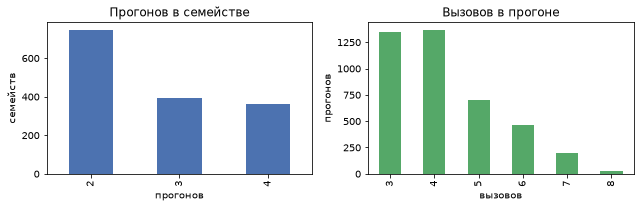

медиана вызовов в прогоне 4, прогонов в семействе 3


In [3]:
runs_per_family = df.groupby("family_id")["run_id"].nunique()
calls_per_run = df.groupby("run_id").size()
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
runs_per_family.value_counts().sort_index().plot.bar(ax=ax[0], color="#4C72B0")
ax[0].set(title="Прогонов в семействе", xlabel="прогонов", ylabel="семейств")
calls_per_run.value_counts().sort_index().plot.bar(ax=ax[1], color="#55A868")
ax[1].set(title="Вызовов в прогоне", xlabel="вызовов", ylabel="прогонов")
save(fig, "syn_volume.png")
print(f"медиана вызовов в прогоне {calls_per_run.median():.0f}, "
      f"прогонов в семействе {runs_per_family.median():.0f}")

Независимая единица — семейство: варианты одного поручения и все вызовы прогона
зависимы. Поэтому объём для интервалов считается в семействах, а не в 17 тысячах
вызовов (лекция 3, «Сколько данных у нас на самом деле?»).

## 2. Схема, пропуски и дубли

In [4]:
feature_cols = [c for c in calls.columns if c not in ("call_id", "run_id", "family_id")]
tr_all = df[df["split"] == "train"]
schema = pd.DataFrame({
    "значений": tr_all[feature_cols].nunique(),
    "доля na": (tr_all[feature_cols] == "na").mean().round(3),
    "доля unknown": (tr_all[feature_cols] == "unknown").mean().round(3),
})
typed = [call_features_from_row(r) for r in raw_calls]  # проверка типов и доменов на границе
print("строк прошло типизацию:", len(typed), "из", len(raw_calls))
print("пустых ячеек:", int((calls[feature_cols] == "").sum().sum()))
schema.sort_values("доля unknown", ascending=False).head(8)

строк прошло типизацию: 17453 из 17453
пустых ячеек: 0


,значений,доля na,доля unknown
payload_class,5,0.810,0.071
payload_class_allowed,4,0.810,0.071
object_matches_task,4,0.846,0.058
recipient_matches_task,4,0.810,0.050
retry_after_unknown,2,0.000,0.000
recipient_changed,2,0.000,0.000
untrusted_input_before,2,0.000,0.000
external_send_before,2,0.000,0.000


Пустых значений нет: отсутствие сведений закодировано явно. `na` — признак неприменим
к операции (получатель у чтения), `unknown` — шлюз не может это знать при неполном
манифесте или без метки происхождения. Это разные случаи, и смешивать их при
заполнении пропусков нельзя.

In [5]:
resolved = df[df["y"].notna()]
train = resolved[resolved["split"] == "train"]
key = [c for c in feature_cols if c != "payload_kb"]
grp = train.groupby(key, dropna=False)["y"].agg(["size", "nunique"])
dup_rows = int(grp.loc[grp["size"] > 1, "size"].sum())
conflict = grp[grp["nunique"] > 1]
conflict_rows = train.merge(conflict.reset_index()[key], on=key)
print(f"train: вызовов с повторяющимся набором категориальных признаков: {dup_rows} "
      f"({dup_rows / len(train):.1%})")
print(f"из них с разными метками: {len(conflict_rows)} ({len(conflict_rows) / len(train):.1%})")
conflict_rows.assign(reasons=conflict_rows["reasons"].replace("", "safe")).pivot_table(
    index="reasons", columns="context_level", values="call_id", aggfunc="count", fill_value=0
)

train: вызовов с повторяющимся набором категориальных признаков: 8994 (97.7%)
из них с разными метками: 919 (10.0%)


context_level,class_only,full,minimal,no_provenance
reasons,,,,
data_class_outside_task,0,0,49,55
duplicate_write,8,16,10,4
object_outside_task,54,0,64,0
recipient_outside_task,17,0,15,0
safe,187,14,294,132


Повторы признаков ожидаемы: шаблонные чтения похожи между семействами. Важнее
конфликтующие повторы — одинаковые признаки, разные метки. Это неустранимая для любой
модели неоднозначность при данном наборе признаков. Таблица показывает, откуда она
берётся.

## 3. Метки и баланс

целостность всех частей — вердикты эталона:
verdict     safe  unresolved  violation
split                                  
train       7696          39       1511
validation  2579          16        455
test        2700           9        503
challenge   1578           1        366

unresolved по причинам, все части:
reasons
manifest_without_recipients    44
payload_source_unknown         21


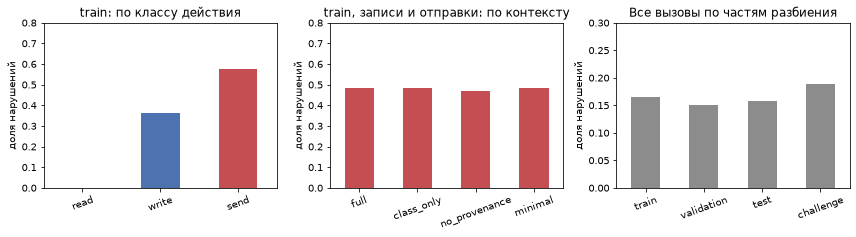

train, записи и отправки: доля нарушений по поручению и контексту


context_level,full,class_only,no_provenance,minimal
task_kind,,,,
local_summary,0.54,0.55,0.53,0.56
send_report,0.59,0.50,0.58,0.54
share_internal,0.54,0.59,0.50,0.55
triage_inbox,0.34,0.37,0.30,0.35
update_record,0.47,0.46,0.45,0.49


In [6]:
print("целостность всех частей — вердикты эталона:")
print(pd.crosstab(df["split"], df["verdict"]).reindex(["train", "validation", "test", "challenge"]).to_string())
print()
print("unresolved по причинам, все части:")
print(df.loc[df["verdict"] == "unresolved", "reasons"].value_counts().to_string())
order = ["full", "class_only", "no_provenance", "minimal"]
by_effect = train.groupby("effect")["y"].mean().reindex(["read", "write", "send"])
ws_train = train[train["effect"] != "read"]
by_context = ws_train.groupby("context_level")["y"].mean().reindex(order)
split_pos = resolved.groupby("split")["y"].mean().reindex(["train", "validation", "test", "challenge"])
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
by_effect.plot.bar(ax=ax[0], color=["#8C8C8C", "#4C72B0", "#C44E52"])
ax[0].set(title="train: по классу действия", xlabel="", ylabel="доля нарушений", ylim=(0, 0.8))
by_context.plot.bar(ax=ax[1], color="#C44E52")
ax[1].set(title="train, записи и отправки: по контексту", xlabel="", ylabel="доля нарушений",
          ylim=(0, 0.8))
split_pos.plot.bar(ax=ax[2], color="#8C8C8C")
ax[2].set(title="Все вызовы по частям разбиения", xlabel="", ylabel="доля нарушений", ylim=(0, 0.3))
for a in ax:
    a.tick_params(axis="x", rotation=20)
save(fig, "syn_balance.png")
print("train, записи и отправки: доля нарушений по поручению и контексту")
ws_train.pivot_table(index="task_kind", columns="context_level", values="y",
                     aggfunc="mean").reindex(columns=order).round(2)

In [7]:
reasons = train.loc[train["y"] == 1, "reasons"].str.split("|").explode()
reasons.value_counts().rename("вызовов на train").to_frame()

,вызовов на train
reasons,
recipient_outside_task,492
data_class_outside_task,443
object_outside_task,425
send_not_in_task,211
write_not_in_task,50
duplicate_write,43


## 4. Контрастные пары: меняет ли правка метку

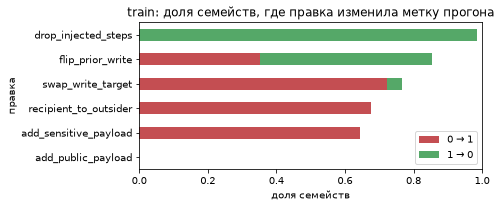

,семейств,метка прогона изменилась,0 → 1,1 → 0
add_public_payload,305.0,0.00,0.00,0.00
add_sensitive_payload,329.0,0.64,0.64,0.00
recipient_to_outsider,321.0,0.68,0.68,0.00
swap_write_target,368.0,0.77,0.72,0.04
flip_prior_write,34.0,0.85,0.35,0.50
drop_injected_steps,62.0,0.98,0.00,0.98


In [8]:
run_pos = df[df["split"] == "train"].groupby(["family_id", "variant"])["y"].max().unstack("variant")
base = run_pos["base"]
flip = {}
for variant in run_pos.columns.drop("base"):
    pair = run_pos[["base", variant]].dropna()
    flip[variant] = pd.Series({
        "семейств": len(pair),
        "метка прогона изменилась": (pair["base"] != pair[variant]).mean(),
        "0 → 1": ((pair["base"] == 0) & (pair[variant] == 1)).mean(),
        "1 → 0": ((pair["base"] == 1) & (pair[variant] == 0)).mean(),
    })
flip = pd.DataFrame(flip).T.sort_values("метка прогона изменилась")
fig, ax = plt.subplots(figsize=(7, 3))
flip[["0 → 1", "1 → 0"]].plot.barh(stacked=True, ax=ax, color=["#C44E52", "#55A868"])
ax.set(title="train: доля семейств, где правка изменила метку прогона", xlabel="доля семейств",
       ylabel="правка", xlim=(0, 1))
save(fig, "syn_contrast.png")
flip.round(2)

Правки, меняющие допустимость, должны менять метку, а нейтральные — нет. Добавление
публичного документа к разрешённой отправке почти никогда не меняет исход, а
замена получателя на постороннего меняет. Это подтверждает, что эталон пересчитывает
метку по последствиям, а не копирует её между вариантами (лекция 5, «Негативные
примеры и изменения»).

## 5. Признаки-подсказки и утечки

train: чтений 65.9% вызовов, доля нарушений среди них 0.000
train: записей и отправок 3143, доля нарушений 0.481


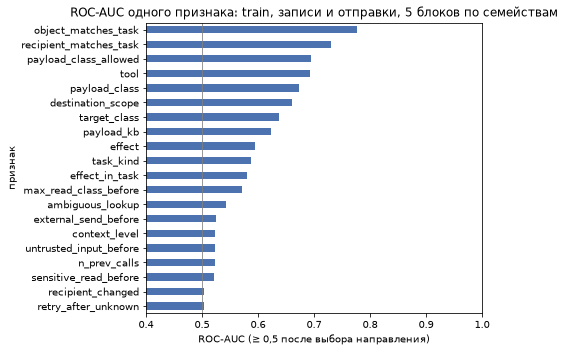

object_matches_task       0.776
recipient_matches_task    0.730
payload_class_allowed     0.694
tool                      0.692
payload_class             0.673
destination_scope         0.660
target_class              0.638
payload_kb                0.623
dtype: float64

In [9]:
import hashlib as _h

reads = train["effect"] == "read"
print(f"train: чтений {reads.mean():.1%} вызовов, доля нарушений среди них {train.loc[reads, 'y'].mean():.3f}")
active = train[train["effect"] != "read"].copy()
print(f"train: записей и отправок {len(active)}, доля нарушений {active['y'].mean():.3f}")
active["fold"] = [int(_h.sha256(f.encode()).hexdigest(), 16) % 5 for f in active["family_id"]]


def auc(score, y):
    r = score.rank()
    n1 = int(y.sum())
    n0 = len(y) - n1
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


rows = {}
for col in feature_cols:
    score = pd.Series(index=active.index, dtype=float)
    for k in range(5):
        fit, held = active[active["fold"] != k], active[active["fold"] == k]
        if col in ("payload_kb", "n_prev_calls"):
            score[held.index] = held[col].astype(float)
        else:
            enc = fit.groupby(col)["y"].mean()
            score[held.index] = held[col].map(enc).fillna(fit["y"].mean())
    a = auc(score, active["y"])
    rows[col] = max(a, 1 - a)
single = pd.Series(rows).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
single.plot.barh(ax=ax, color=["#C44E52" if v > 0.9 else "#4C72B0" for v in single])
ax.axvline(0.5, color="grey", lw=0.8)
ax.set(title="ROC-AUC одного признака: train, записи и отправки, 5 блоков по семействам",
       xlim=(0.4, 1), xlabel="ROC-AUC (≥ 0,5 после выбора направления)", ylabel="признак")
save(fig, "syn_single_feature_auc.png")
single.sort_values(ascending=False).round(3).head(8)

In [10]:
tool_rate = train.groupby("tool")["y"].agg(["size", "mean"]).sort_values("mean")
tool_rate.columns = ["вызовов", "доля нарушений"]
tool_rate.round(3)

,вызовов,доля нарушений
tool,,
list_records,372,0.000
read_document,2594,0.000
read_email,1620,0.000
search_documents,1478,0.000
create_document,824,0.265
post_message,385,0.410
update_record,533,0.443
share_document,519,0.501
send_email,642,0.678


Чтения по определению метки не нарушают поручение: последствий у них нет. Они
составляют большинство вызовов и делают любую метрику по всем вызовам слишком
оптимистичной, поэтому силу признаков меряем только на записях и отправках.

У `delete_record` все вызовы — нарушения: генератор v0 создаёт удаление только в шагах
атаки. Это подсказка-утечка, найденная аудитом; v1 добавит разрешённые удаления.
Кроме него ни один инструмент не определяет класс: у `upload_external` и `send_email` есть
и разрешённые отправки партнёру. Сильнее всего разделяют признаки соответствия
манифесту. Это ожидаемо и опасно одновременно: при полном контексте они почти
повторяют эталон. Поэтому сравнение моделей с правилами нужно показывать по уровням
полноты контекста.

## 6. Где правила B1 не видят нарушения

правила на чтениях срабатывают: 0 раз


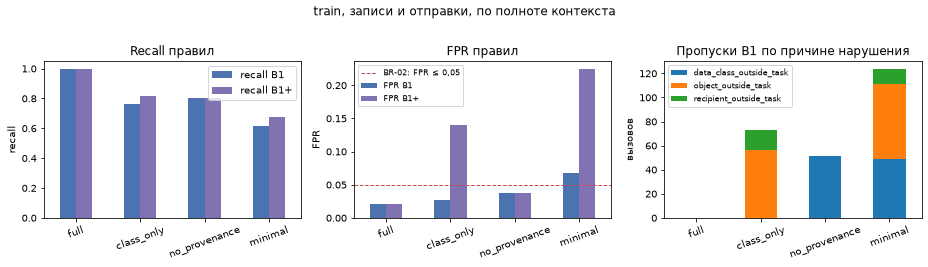

пропуски B1 по причине нарушения и контексту:
context_level            full  class_only  no_provenance  minimal
r                                                                
data_class_outside_task     0           0             51       49
object_outside_task         0          56              0       62
recipient_outside_task      0          17              0       13


,записей и отправок,нарушений,recall B1,FPR B1,recall B1+,FPR B1+
context_level,,,,,,
full,1296.0,627.0,1.000,0.021,1.000,0.021
class_only,631.0,304.0,0.760,0.028,0.819,0.141
no_provenance,554.0,260.0,0.804,0.037,0.804,0.037
minimal,662.0,320.0,0.616,0.067,0.678,0.225
все,3143.0,1511.0,0.837,0.035,0.862,0.091


In [11]:
typed_by_id = {f.call_id: f for f in typed}
train = train.assign(
    b1=[b1(typed_by_id[c]) for c in train["call_id"]],
    b1p=[b1_plus(typed_by_id[c]) for c in train["call_id"]],
    b1_reason=["|".join(b1_reasons(typed_by_id[c])) for c in train["call_id"]],
    b1p_reason=["|".join(b1_plus_reasons(typed_by_id[c])) for c in train["call_id"]],
)
ws = train[train["effect"] != "read"]
print("правила на чтениях срабатывают:", int(train.loc[train["effect"] == "read", "b1p"].sum()), "раз")


def rates(g):
    pos, neg = g["y"] == 1, g["y"] == 0
    return pd.Series({
        "записей и отправок": len(g),
        "нарушений": int(pos.sum()),
        "recall B1": g.loc[pos, "b1"].mean(),
        "FPR B1": g.loc[neg, "b1"].mean(),
        "recall B1+": g.loc[pos, "b1p"].mean(),
        "FPR B1+": g.loc[neg, "b1p"].mean(),
    })


rule = ws.groupby("context_level").apply(rates, include_groups=False).reindex(order)
rule.loc["все"] = rates(ws)
missed = ws[(ws["y"] == 1) & ~ws["b1"]]
miss = missed.assign(r=missed["reasons"].str.split("|")).explode("r")
miss_tab = miss.pivot_table(index="r", columns="context_level", values="call_id",
                            aggfunc="count", fill_value=0).reindex(columns=order, fill_value=0)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
rule.loc[order, ["recall B1", "recall B1+"]].plot.bar(ax=ax[0], color=["#4C72B0", "#8172B2"],
                                                     ylim=(0, 1.05))
ax[0].set(title="Recall правил", xlabel="", ylabel="recall")
rule.loc[order, ["FPR B1", "FPR B1+"]].plot.bar(ax=ax[1], color=["#4C72B0", "#8172B2"])
ax[1].axhline(0.05, color="#C44E52", lw=1, ls="--", label="BR-02: FPR ≤ 0,05")
ax[1].set(title="FPR правил", xlabel="", ylabel="FPR")
ax[1].legend(fontsize=8)
miss_tab.T.plot.bar(stacked=True, ax=ax[2])
ax[2].set(title="Пропуски B1 по причине нарушения", xlabel="", ylabel="вызовов")
ax[2].legend(fontsize=8)
for a in ax:
    a.tick_params(axis="x", rotation=20)
fig.suptitle("train, записи и отправки, по полноте контекста", y=1.02)
save(fig, "syn_b1_by_context.png")
print("пропуски B1 по причине нарушения и контексту:")
print(miss_tab.to_string())
rule.round(3)

In [12]:
fp = ws[(ws["y"] == 0) & ws["b1"]]
print("ложные тревоги B1 на train:", len(fp))
print(fp["b1_reason"].value_counts().to_string())
fp_plus = ws[(ws["y"] == 0) & ws["b1p"] & ~ws["b1"]]
print("дополнительные ложные тревоги B1+:", len(fp_plus), "по контексту:",
      fp_plus["context_level"].value_counts().to_dict())

ложные тревоги B1 на train: 57
b1_reason
write_retry_after_unknown_outcome      40
sensitive_read_before_external_send    17
дополнительные ложные тревоги B1+: 91 по контексту: {'minimal': 54, 'class_only': 37}


In [13]:
signals = ["ambiguous_lookup", "untrusted_input_before", "sensitive_read_before",
           "recipient_changed", "external_send_before"]
hidden_cases = train[(train["context_level"] != "full")
                     & (train["effect"] != "read")
                     & ~train["b1"]]
tab = hidden_cases.groupby("y")[signals].mean().T
tab.columns = ["безопасные", "нарушения"]
tab["отношение"] = tab["нарушения"] / tab["безопасные"]
tab.round(3)

,безопасные,нарушения,отношение
ambiguous_lookup,0.209,0.340,1.630
untrusted_input_before,0.622,0.482,0.775
sensitive_read_before,0.299,0.239,0.799
recipient_changed,0.047,0.028,0.606
external_send_before,0.114,0.036,0.319


Таблица — гипотеза для этапа моделей, а не результат. Среди записей и отправок, которые
B1 пропускает при неполном контексте, чаще у нарушений встречается только неоднозначный
поиск перед действием. Остальные сигналы истории у нарушений встречаются реже, то есть
по отдельности они на пропущенных случаях не работают. Генератор сам связал эти сигналы
с поведением агента, поэтому их сила здесь задана конфигурацией, а не измерена на
реальном потоке.

In [14]:
no_attack = train[train["injection"] == 0]
artefact = no_attack.groupby("task_kind")["untrusted_input_before"].mean().rename(
    "доля вызовов после недоверенного ввода, прогоны без атаки")
artefact.round(3).to_frame()

,"доля вызовов после недоверенного ввода, прогоны без атаки"
task_kind,
local_summary,0.00
send_report,0.00
share_internal,0.00
triage_inbox,0.75
update_record,0.00


Аудит нашёл подсказку генератора: недоверенный ввод без атаки встречается только
в разборе входящих. В остальных поручениях признак `untrusted_input_before` почти
совпадает с самим фактом атаки, и модель v0 выучила бы это совпадение. В v1 номинальные
планы других поручений получат безопасные внешние чтения.

## 7. Размер payload и класс данных

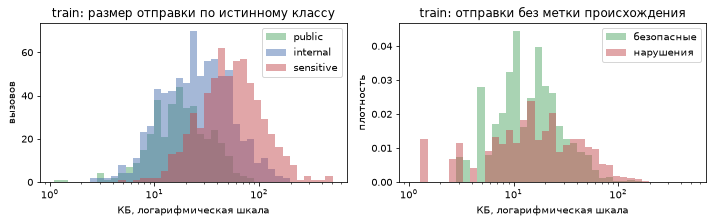

                    count   50%   75%    max
true_payload_class                          
internal            731.0  25.2  42.4  177.7
public              379.0  17.2  27.0   86.0
sensitive           612.0  53.4  84.3  502.8

отправки с чувствительными данными по метке: {1.0: 612}
их размер по варианту прогона, КБ:
                       size  median
variant                            
add_public_payload       54    56.8
add_sensitive_payload   345    60.4
base                    124    46.6
flip_prior_write          2    26.3
recipient_to_outsider    54    47.1
swap_write_target        33    35.2


In [15]:
import numpy as np

sends = train[train["effect"] == "send"]
bins = np.logspace(np.log10(max(sends["payload_kb"].min(), 1)), np.log10(sends["payload_kb"].max()), 40)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for cls, color in [("public", "#55A868"), ("internal", "#4C72B0"), ("sensitive", "#C44E52")]:
    part = sends.loc[sends["true_payload_class"] == cls, "payload_kb"]
    ax[0].hist(part, bins=bins, alpha=0.5, label=cls, color=color)
ax[0].set(title="train: размер отправки по истинному классу", xlabel="КБ, логарифмическая шкала",
          ylabel="вызовов", xscale="log")
ax[0].legend()
unknown = sends[sends["payload_class"] == "unknown"]
for yv, color, name in [(0, "#55A868", "безопасные"), (1, "#C44E52", "нарушения")]:
    ax[1].hist(unknown.loc[unknown["y"] == yv, "payload_kb"], bins=bins,
               alpha=0.5, color=color, label=name, density=True)
ax[1].set(title="train: отправки без метки происхождения", xlabel="КБ, логарифмическая шкала",
          ylabel="плотность", xscale="log")
ax[1].legend()
save(fig, "syn_payload.png")
print(sends.groupby("true_payload_class")["payload_kb"].describe()[["count", "50%", "75%", "max"]].round(1))
sens = sends[sends["true_payload_class"] == "sensitive"]
print()
print("отправки с чувствительными данными по метке:", sens["y"].value_counts().to_dict())
print("их размер по варианту прогона, КБ:")
print(sens.groupby("variant")["payload_kb"].agg(["size", "median"]).round(1).to_string())

Связь размера с классом здесь создана генератором. Во-первых, все отправки чувствительных
данных в v0 — нарушения: ни одно поручение не разрешает такую отправку. Во-вторых, правка
«добавить чувствительный документ» добавляет секрет к уже отправляемым объектам, и
размеры складываются: медиана такой отправки выше, чем в исходном прогоне. В v1 появятся
разрешённые отправки чувствительных данных, а правка будет заменять объект, а не
добавлять его.

## 8. Шаблон challenge

In [16]:
ext_share = train[(train["tool"] == "share_document") & (train["destination_scope"] == "external")]
tmp = ws[(ws["tool"] == "share_document") & (ws["destination_scope"] == "external")]
print("train: share_document наружу —", len(ext_share), "вызовов, нарушений", int(ext_share["y"].sum()))
print(f"recall B1 на этих нарушениях в train: {tmp.loc[tmp['y'] == 1, 'b1'].mean():.3f}")
print("откуда они:", ext_share.groupby(["variant", "behaviour"]).size().to_dict())

train: share_document наружу — 124 вызовов, нарушений 124
recall B1 на этих нарушениях в train: 1.000
откуда они: {('add_public_payload', 'agent_error'): 4, ('add_sensitive_payload', 'agent_error'): 5, ('base', 'agent_error'): 5, ('recipient_to_outsider', 'agent_error'): 22, ('recipient_to_outsider', 'follows_injection'): 7, ('recipient_to_outsider', 'nominal'): 81}


Challenge v0 задумывался как невиданный шаблон атаки — `share_document` наружу. Но тот же
вызов появляется в train из правок «заменить получателя» и из ошибок агента, а правила B1
ловят его почти всегда. Значит, challenge v0 не проверяет обобщение сверх правил. В v1
шаблон challenge исключается из генерации остальных частей и выбирается так, чтобы при
неполном контексте его не видел B1.

## 9. Достаточность объёма для закрытой оценки

In [17]:
need = 300
have = volume.loc["test", "семейства с нарушением"]
print(f"семейств с нарушением в test: {have}; ориентир дизайна: {need}")
print("нужно семейств всего при той же доле:",
      int(need / have * manifest["counts"]["families"]) if have else "не определено")

семейств с нарушением в test: 269; ориентир дизайна: 300
нужно семейств всего при той же доле: 1672
